In [ ]:

!pip install -q yfinance

import pandas as pd
import numpy as np
import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
sns.set_theme(style="whitegrid")


In [ ]:

TICKERS = ["SPY", "GLD", "CL=F", "EURUSD=X", "^VIX"]

START_DATE = "2010-01-01"
END_DATE = "2026-01-01"

BASELINE_WINDOW = 20
ROBUSTNESS_WINDOW = 15

CLUSTER_VALUES = [2, 3, 4, 5]
RANDOM_STATE = 42

PCA_VARIANCE_THRESHOLD = 0.95


In [ ]:

raw_data = yf.download(
    tickers=TICKERS,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = raw_data["Close"].copy()
prices = prices[TICKERS]

print("Dataset shape:", prices.shape)
display(prices.head())
display(prices.tail())


Dataset shape: (4171, 5)


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2010-01-01,NaN,NaN,NaN,1.438994,NaN
2010-01-04,84.368996,109.800003,81.510002,1.442398,20.040001
2010-01-05,84.592293,109.699997,81.769997,1.436596,19.350000
2010-01-06,84.651855,111.510002,83.180000,1.440403,19.160000
2010-01-07,85.009193,110.820000,82.660004,1.431803,19.059999


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2025-12-24,685.029480,411.929993,58.349998,1.179551,13.47
2025-12-26,684.960022,416.739990,56.740002,1.178536,13.60
2025-12-29,682.519043,398.600006,58.080002,1.177274,14.20
2025-12-30,681.685547,398.890015,57.950001,1.177288,14.33
2025-12-31,676.635010,396.309998,57.419998,1.174729,14.95


Preproccessing

In [ ]:

print("Dataset shape:", prices.shape)

print("\nData types:")
print(prices.dtypes)

print("\nMissing values:")
print(prices.isnull().sum())

print("\nDuplicate dates:", prices.index.duplicated().sum())

print("\nDate range:")
print(prices.index.min(), "to", prices.index.max())

display(prices.describe())


Dataset shape: (4171, 5)

Data types:
Ticker
SPY         float64
GLD         float64
CL=F        float64
EURUSD=X    float64
^VIX        float64
dtype: object

Missing values:
Ticker
SPY         147
GLD         147
CL=F        147
EURUSD=X      6
^VIX        147
dtype: int64

Duplicate dates: 0

Date range:
2010-01-01 00:00:00 to 2025-12-31 00:00:00


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
count,4024.000000,4024.000000,4024.000000,4165.000000,4024.000000
mean,266.719016,157.267403,71.543295,1.186451,18.412875
std,154.812246,52.534301,20.792733,0.112087,6.873274
min,76.759995,100.500000,-37.630001,0.959619,9.140000
25%,145.487259,121.110001,54.187499,1.097767,13.770000
50%,226.641602,143.724998,71.564999,1.155668,16.660000
75%,384.443581,172.085003,88.265001,1.285000,21.100000
max,685.029480,416.739990,123.699997,1.484406,82.690002


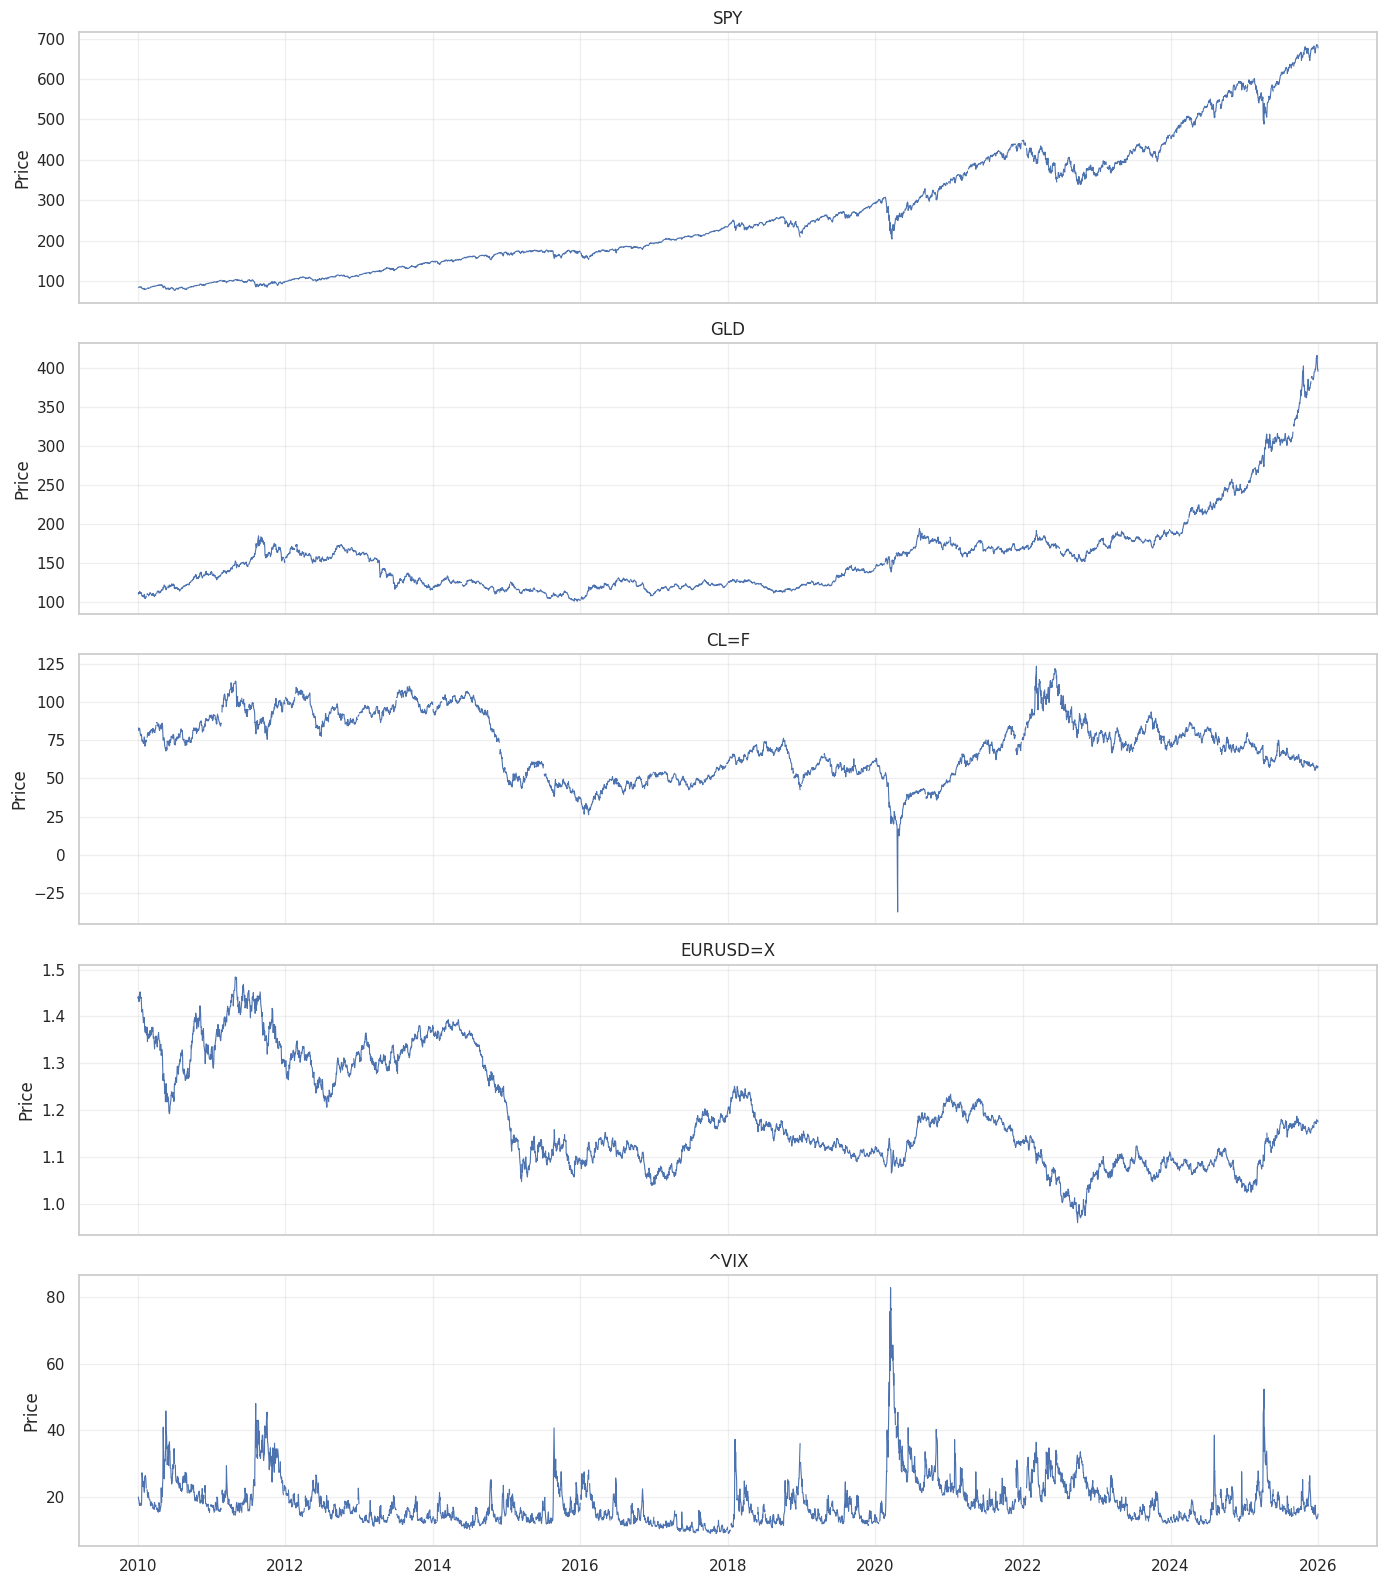

In [ ]:

fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

for i, ticker in enumerate(TICKERS):
    axes[i].plot(prices.index, prices[ticker], linewidth=0.8)
    axes[i].set_title(ticker)
    axes[i].set_ylabel("Price")
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

prices_clean = prices.copy()

prices_clean.index = pd.to_datetime(prices_clean.index)
prices_clean = prices_clean.sort_index()
prices_clean = prices_clean[~prices_clean.index.duplicated(keep="first")]

prices_clean = prices_clean.replace([np.inf, -np.inf], np.nan)
prices_clean = prices_clean.dropna(subset=TICKERS)

# CL=F settled at -37.63 on 2020-04-20; negative prices break returns, momentum and drawdown
bad_rows = prices_clean[(prices_clean <= 0).any(axis=1)]
print("Rows removed because of non-positive prices:")
display(bad_rows)
prices_clean = prices_clean[(prices_clean > 0).all(axis=1)]

print("Original shape:", prices.shape)
print("Cleaned shape:", prices_clean.shape)

print("\nMissing values:")
print(prices_clean.isnull().sum())

print("\nFinal date range:")
print(prices_clean.index.min(), "to", prices_clean.index.max())

display(prices_clean.head())


Rows removed because of non-positive prices:


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2020-04-20,257.544556,159.699997,-37.630001,1.086697,43.830002


Original shape: (4171, 5)
Cleaned shape: (4015, 5)

Missing values:
Ticker
SPY         0
GLD         0
CL=F        0
EURUSD=X    0
^VIX        0
dtype: int64

Final date range:
2010-01-04 00:00:00 to 2025-12-31 00:00:00


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2010-01-04,84.368996,109.800003,81.510002,1.442398,20.040001
2010-01-05,84.592293,109.699997,81.769997,1.436596,19.350000
2010-01-06,84.651855,111.510002,83.180000,1.440403,19.160000
2010-01-07,85.009193,110.820000,82.660004,1.431803,19.059999
2010-01-08,85.292107,111.370003,82.750000,1.441109,18.129999


In [ ]:

prices_clean.to_csv("/content/cleaned_market_prices.csv")

print("Cleaned dataset saved.")


Cleaned dataset saved.


FEATURE ENGINEERING

Daily Returns

In [ ]:

returns = prices_clean.pct_change()

display(returns.head())


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.002647,-0.000911,0.003190,-0.004022,-0.034431
2010-01-06,0.000704,0.016500,0.017244,0.002650,-0.009819
2010-01-07,0.004221,-0.006188,-0.006251,-0.005971,-0.005219
2010-01-08,0.003328,0.004963,0.001089,0.006499,-0.048793


Rolling volatility

In [ ]:

volatility = returns.rolling(window=BASELINE_WINDOW).std()

display(volatility.head(25))


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN
2010-01-05,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN,NaN,NaN
2010-01-12,NaN,NaN,NaN,NaN,NaN
2010-01-13,NaN,NaN,NaN,NaN,NaN
2010-01-14,NaN,NaN,NaN,NaN,NaN


Momentum

In [ ]:

momentum = prices_clean.pct_change(periods=BASELINE_WINDOW)

display(momentum.head(25))


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN
2010-01-05,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN,NaN,NaN
2010-01-12,NaN,NaN,NaN,NaN,NaN
2010-01-13,NaN,NaN,NaN,NaN,NaN
2010-01-14,NaN,NaN,NaN,NaN,NaN


Drawdown

In [ ]:

rolling_peak = prices_clean.rolling(
    window=BASELINE_WINDOW
).max()

drawdown = (prices_clean / rolling_peak) - 1

display(drawdown.head(25))


Ticker,SPY,GLD,CL=F,EURUSD=X,^VIX
Date,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN
2010-01-05,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN,NaN,NaN
2010-01-12,NaN,NaN,NaN,NaN,NaN
2010-01-13,NaN,NaN,NaN,NaN,NaN
2010-01-14,NaN,NaN,NaN,NaN,NaN


ALL features combined in a dataframe

In [ ]:

features = pd.concat(
    {
        "returns": returns,
        "volatility": volatility,
        "momentum": momentum,
        "drawdown": drawdown
    },
    axis=1
)

features.columns = [
    f"{feature}_{ticker}"
    for feature, ticker in features.columns
]

features = features.replace([np.inf, -np.inf], np.nan)
features = features.dropna()

print("Feature matrix shape:", features.shape)

display(features.head())


Feature matrix shape: (3995, 20)


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX,momentum_SPY,momentum_GLD,momentum_CL=F,momentum_EURUSD=X,momentum_^VIX,drawdown_SPY,drawdown_GLD,drawdown_CL=F,drawdown_EURUSD=X,drawdown_^VIX
Date,,,,,,,,,,,,,,,,,,,,
2010-02-02,0.012104,0.007199,0.037619,0.003536,-0.049137,0.010585,0.011775,0.015850,0.005274,0.079265,-0.026030,-0.006102,-0.052509,-0.031041,0.071856,-0.040674,-0.032964,-0.071532,-0.037708,-0.213475
2010-02-03,-0.004983,-0.003940,-0.003237,-0.005380,0.005587,0.010574,0.011804,0.015792,0.005316,0.078688,-0.033442,-0.009116,-0.058579,-0.032362,0.116279,-0.045454,-0.036774,-0.074537,-0.042885,-0.209081
2010-02-04,-0.030866,-0.039834,-0.049883,-0.011230,0.207407,0.012403,0.014066,0.018231,0.005624,0.090214,-0.063934,-0.064030,-0.120702,-0.045757,0.361169,-0.074917,-0.075144,-0.116133,-0.053633,-0.045038
2010-02-05,0.002067,0.002970,-0.026661,-0.004720,0.001150,0.012344,0.014113,0.018794,0.005589,0.090135,-0.065942,-0.055405,-0.138761,-0.044556,0.369885,-0.073005,-0.072397,-0.139698,-0.058099,-0.043940
2010-02-08,-0.007220,-0.006114,0.009833,-0.001857,0.015320,0.012270,0.014011,0.019098,0.005198,0.088710,-0.075762,-0.065817,-0.131239,-0.052489,0.462217,-0.079698,-0.078068,-0.128817,-0.059848,-0.029293


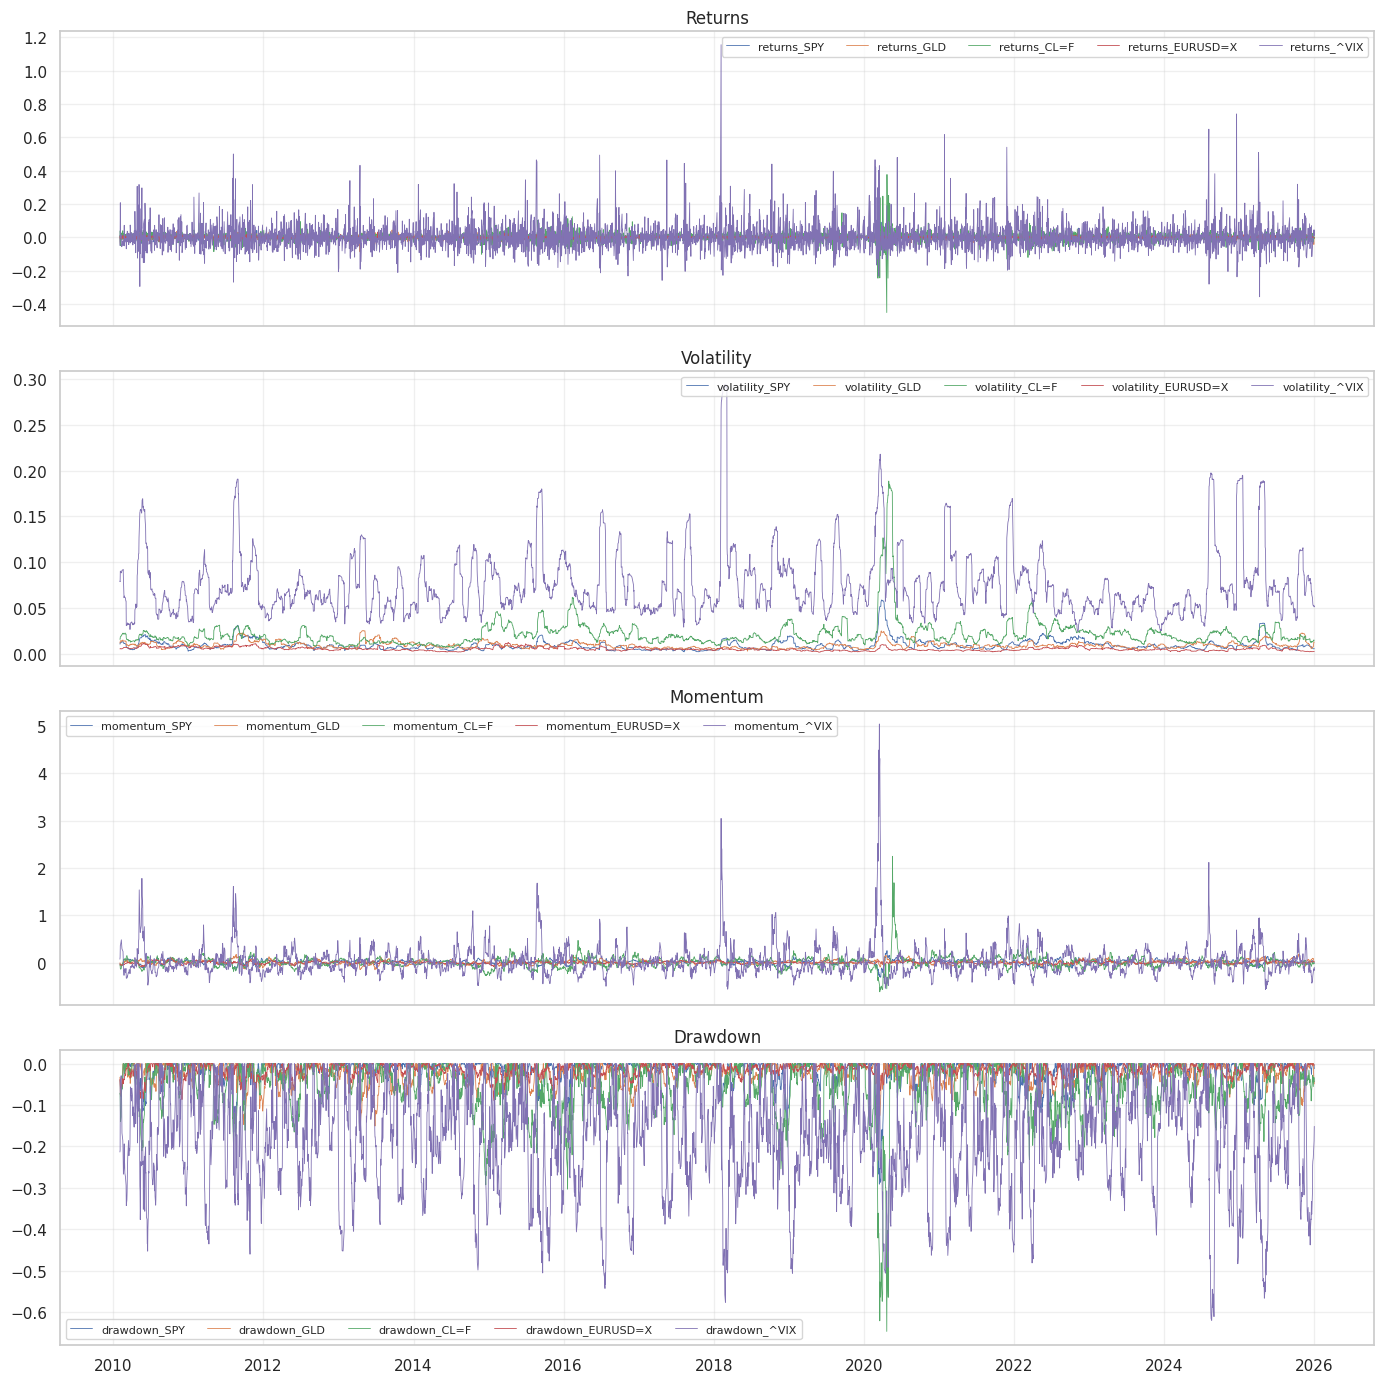

In [ ]:

feature_types = ["returns", "volatility", "momentum", "drawdown"]

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)

for i, feature in enumerate(feature_types):
    cols = [col for col in features.columns if col.startswith(feature + "_")]

    for col in cols:
        axes[i].plot(features.index, features[col], linewidth=0.6, label=col)

    axes[i].set_title(feature.capitalize())
    axes[i].legend(ncol=5, fontsize=8)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

features.to_csv("/content/market_features_20day.csv")

print("Feature matrix saved successfully.")


Feature matrix saved successfully.


In [ ]:

print("Number of observations:", len(features))
print("Number of features:", features.shape[1])
print("Missing values:", features.isnull().sum().sum())
print("Infinite values:", np.isinf(features.to_numpy()).sum())

assert features.shape[1] == 20
assert features.isnull().sum().sum() == 0
assert np.isfinite(features.to_numpy()).all()

print("\nFeature engineering completed successfully.")


Number of observations: 3995
Number of features: 20
Missing values: 0
Infinite values: 0

Feature engineering completed successfully.


Standardization of Feature Matrix

In [ ]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(features)

X_scaled = pd.DataFrame(
    X_scaled,
    index=features.index,
    columns=features.columns
)

print("Standardized matrix shape:", X_scaled.shape)
display(X_scaled.head())


Standardized matrix shape: (3995, 20)


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX,momentum_SPY,momentum_GLD,momentum_CL=F,momentum_EURUSD=X,momentum_^VIX,drawdown_SPY,drawdown_GLD,drawdown_CL=F,drawdown_EURUSD=X,drawdown_^VIX
Date,,,,,,,,,,,,,,,,,,,,
2010-02-02,1.061206,0.685384,1.401521,0.653948,-0.628774,0.227365,0.689762,-0.361215,0.073599,0.096627,-0.896627,-0.315017,-0.475306,-1.320475,0.115197,-0.794920,-0.390238,-0.248271,-1.603145,-0.252389
2010-02-03,-0.513642,-0.433319,-0.132762,-0.982087,0.030461,0.225491,0.697711,-0.364893,0.095778,0.080665,-1.074019,-0.385418,-0.525449,-1.377969,0.250170,-0.964700,-0.552657,-0.295061,-1.968603,-0.216799
2010-02-04,-2.899221,-4.038158,-1.884464,-2.055574,2.461728,0.540021,1.327858,-0.210141,0.259297,0.399360,-1.803861,-1.668219,-1.038642,-1.961219,0.994233,-2.011127,-2.188180,-0.942627,-2.727368,1.111894
2010-02-05,0.136158,0.260696,-1.012408,-0.860954,-0.022982,0.529901,1.340919,-0.174457,0.240318,0.397172,-1.851919,-1.466740,-1.187826,-1.908926,1.020714,-1.943207,-2.071088,-1.309486,-3.042677,1.120792
2010-02-08,-0.719815,-0.651614,0.358053,-0.335680,0.147713,0.517101,1.312600,-0.155171,0.033442,0.357791,-2.086953,-1.709953,-1.125683,-2.254319,1.301254,-2.180913,-2.312828,-1.140096,-3.166160,1.239425


In [ ]:

print("Feature means:")
print(X_scaled.mean().round(4))

print("\nFeature standard deviations:")
print(X_scaled.std().round(4))


Feature means:
returns_SPY            0.0
returns_GLD            0.0
returns_CL=F          -0.0
returns_EURUSD=X       0.0
returns_^VIX          -0.0
volatility_SPY        -0.0
volatility_GLD        -0.0
volatility_CL=F       -0.0
volatility_EURUSD=X    0.0
volatility_^VIX       -0.0
momentum_SPY           0.0
momentum_GLD           0.0
momentum_CL=F          0.0
momentum_EURUSD=X     -0.0
momentum_^VIX         -0.0
drawdown_SPY           0.0
drawdown_GLD           0.0
drawdown_CL=F          0.0
drawdown_EURUSD=X     -0.0
drawdown_^VIX         -0.0
dtype: float64

Feature standard deviations:
returns_SPY            1.0001
returns_GLD            1.0001
returns_CL=F           1.0001
returns_EURUSD=X       1.0001
returns_^VIX           1.0001
volatility_SPY         1.0001
volatility_GLD         1.0001
volatility_CL=F        1.0001
volatility_EURUSD=X    1.0001
volatility_^VIX        1.0001
momentum_SPY           1.0001
momentum_GLD           1.0001
momentum_CL=F          1.0001
momentum_E

PCA

In [ ]:

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_results = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

display(pca_results)


,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.220259,0.220259
1,PC2,0.128904,0.349163
2,PC3,0.119347,0.468511
3,PC4,0.075691,0.544202
4,PC5,0.068317,0.612519
5,PC6,0.063433,0.675952
6,PC7,0.051728,0.727680
7,PC8,0.045802,0.773481
8,PC9,0.043861,0.817342
9,PC10,0.041347,0.858689


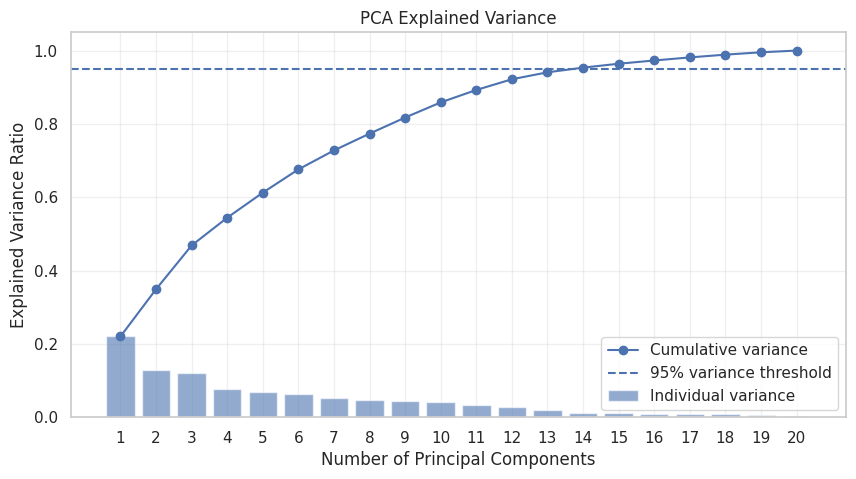

In [ ]:

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.6,
    label="Individual variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    label="Cumulative variance"
)

plt.axhline(
    y=PCA_VARIANCE_THRESHOLD,
    linestyle="--",
    label="95% variance threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.xticks(range(1, 21))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [ ]:

n_components = np.argmax(
    cumulative_variance >= PCA_VARIANCE_THRESHOLD
) + 1

print("Selected components:", n_components)

print(
    "Cumulative explained variance:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)


Selected components: 14
Cumulative explained variance: 95.35 %


In [ ]:

pca_final = PCA(n_components=n_components)

X_reduced = pca_final.fit_transform(X_scaled)

pca_columns = [
    f"PC{i+1}" for i in range(n_components)
]

X_reduced = pd.DataFrame(
    X_reduced,
    index=features.index,
    columns=pca_columns
)

print("Original dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_reduced.shape)

display(X_reduced.head())


Original dimensions: (3995, 20)
Reduced dimensions: (3995, 14)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14
Date,,,,,,,,,,,,,,
2010-02-02,-1.305978,1.522693,-0.625461,-1.741452,-0.231923,0.381031,0.906082,-0.291699,1.172650,0.190183,0.486152,0.726491,-0.432633,0.132910
2010-02-03,-2.120614,0.477088,-1.840955,-0.793798,0.453370,0.074604,-0.476134,-0.370387,-0.314741,-0.112347,0.157728,0.573298,-0.815336,-0.255191
2010-02-04,-5.073992,-1.526999,-5.308513,2.093272,0.252825,0.020632,-1.399484,0.042601,-2.287250,0.516854,0.642221,1.136036,-0.920026,0.072646
2010-02-05,-4.475873,0.693579,-3.329776,-1.031923,0.109942,-0.473201,0.687682,-0.499509,0.393911,-0.578441,-0.945617,0.424647,-0.114400,0.090786
2010-02-08,-4.725509,0.441835,-3.854439,-0.917813,-0.406311,0.337272,0.909846,0.175204,0.528676,0.088751,0.202670,0.896542,-0.496284,-0.323260


In [ ]:

X_reduced.to_csv("/content/pca_reduced_features.csv")

print("PCA results saved successfully.")


PCA results saved successfully.


K Means

In [ ]:

results = []
models = {}

for k in CLUSTER_VALUES:

    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = kmeans.fit_predict(X_reduced)

    silhouette = silhouette_score(X_reduced, labels)
    db_index = davies_bouldin_score(X_reduced, labels)

    models[k] = {
        "model": kmeans,
        "labels": labels
    }

    results.append({
        "k": k,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Inertia": kmeans.inertia_
    })

results_df = pd.DataFrame(results)

display(results_df)


,k,Silhouette Score,Davies-Bouldin Index,Inertia
0,2,0.294647,2.155200,66518.171368
1,3,0.138247,2.254341,61305.013757
2,4,0.155292,2.089693,57575.094302
3,5,0.154219,1.866265,54527.486471


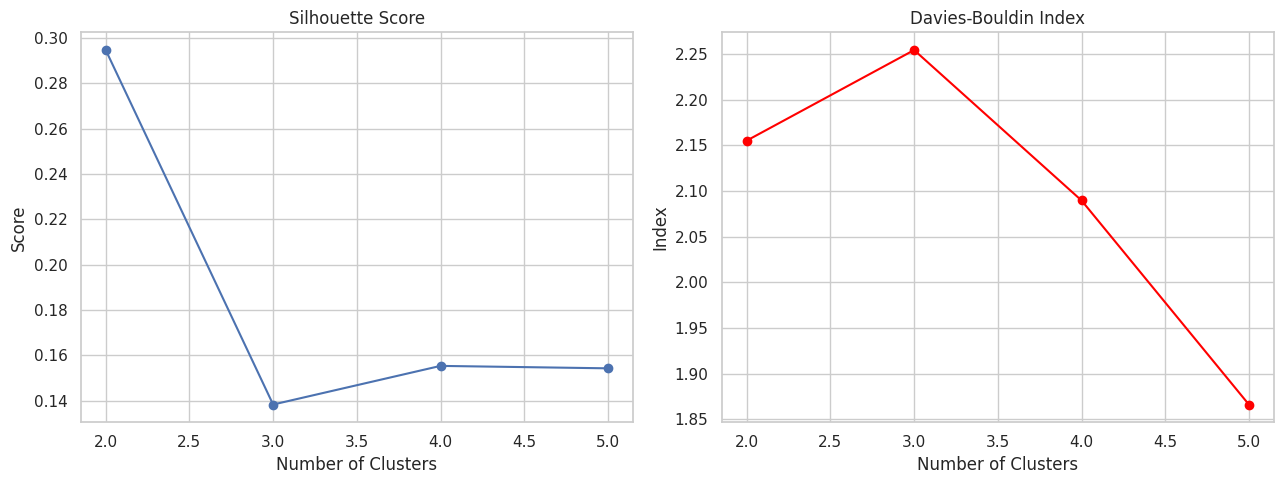

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    results_df["k"],
    results_df["Silhouette Score"],
    marker="o"
)
axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Score")

axes[1].plot(
    results_df["k"],
    results_df["Davies-Bouldin Index"],
    marker="o",
    color="red"
)
axes[1].set_title("Davies-Bouldin Index")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Index")

plt.tight_layout()
plt.show()


In [ ]:

for k in CLUSTER_VALUES:

    labels = models[k]["labels"]

    print(f"\nNumber of clusters: {k}")
    print(pd.Series(labels).value_counts().sort_index())



Number of clusters: 2
0    3266
1     729
Name: count, dtype: int64

Number of clusters: 3
0     449
1    1090
2    2456
Name: count, dtype: int64

Number of clusters: 4
0     129
1     567
2     949
3    2350
Name: count, dtype: int64

Number of clusters: 5
0     394
1     524
2    2213
3      22
4     842
Name: count, dtype: int64


In [ ]:

print("Best Silhouette Score:")
display(
    results_df.sort_values(
        "Silhouette Score",
        ascending=False
    )
)

print("Best Davies-Bouldin Index:")
display(
    results_df.sort_values(
        "Davies-Bouldin Index"
    )
)


Best Silhouette Score:


,k,Silhouette Score,Davies-Bouldin Index,Inertia
0,2,0.294647,2.155200,66518.171368
2,4,0.155292,2.089693,57575.094302
3,5,0.154219,1.866265,54527.486471
1,3,0.138247,2.254341,61305.013757


Best Davies-Bouldin Index:


,k,Silhouette Score,Davies-Bouldin Index,Inertia
3,5,0.154219,1.866265,54527.486471
2,4,0.155292,2.089693,57575.094302
0,2,0.294647,2.155200,66518.171368
1,3,0.138247,2.254341,61305.013757


Ideal Cluster Coefficient k = 2

In [ ]:

best_k = 2

best_model = models[best_k]["model"]
best_labels = models[best_k]["labels"]

regime_data = features.copy()
regime_data["regime"] = best_labels

print("Selected number of regimes:", best_k)
print(regime_data["regime"].value_counts().sort_index())


Selected number of regimes: 2
regime
0    3266
1     729
Name: count, dtype: int64


In [ ]:

regime_profiles = regime_data.groupby("regime").mean()

display(regime_profiles.round(5))


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX,momentum_SPY,momentum_GLD,momentum_CL=F,momentum_EURUSD=X,momentum_^VIX,drawdown_SPY,drawdown_GLD,drawdown_CL=F,drawdown_EURUSD=X,drawdown_^VIX
regime,,,,,,,,,,,,,,,,,,,,
0,0.00174,0.00040,0.00197,0.00020,-0.00479,0.00789,0.00899,0.01952,0.00486,0.06820,0.02291,0.00743,0.02411,0.00250,-0.04518,-0.00938,-0.02267,-0.04109,-0.01229,-0.18871
1,-0.00454,0.00024,-0.00721,-0.00107,0.03823,0.01539,0.01067,0.03060,0.00637,0.10967,-0.04001,0.00715,-0.08046,-0.01513,0.38843,-0.05823,-0.02890,-0.12053,-0.02714,-0.15364


Average returns by regime

In [ ]:

return_cols = [
    col for col in features.columns
    if col.startswith("returns_")
]

regime_returns = regime_data.groupby("regime")[return_cols].mean()

display(regime_returns)


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX
regime,,,,,
0,0.001735,0.000403,0.001975,0.000205,-0.004792
1,-0.004541,0.000245,-0.007213,-0.001068,0.038225


average volatility by regime

In [ ]:

volatility_cols = [
    col for col in features.columns
    if col.startswith("volatility_")
]

regime_volatility = regime_data.groupby("regime")[volatility_cols].mean()

display(regime_volatility)


,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX
regime,,,,,
0,0.007895,0.008993,0.019522,0.004859,0.068204
1,0.015391,0.010674,0.030599,0.006368,0.109669


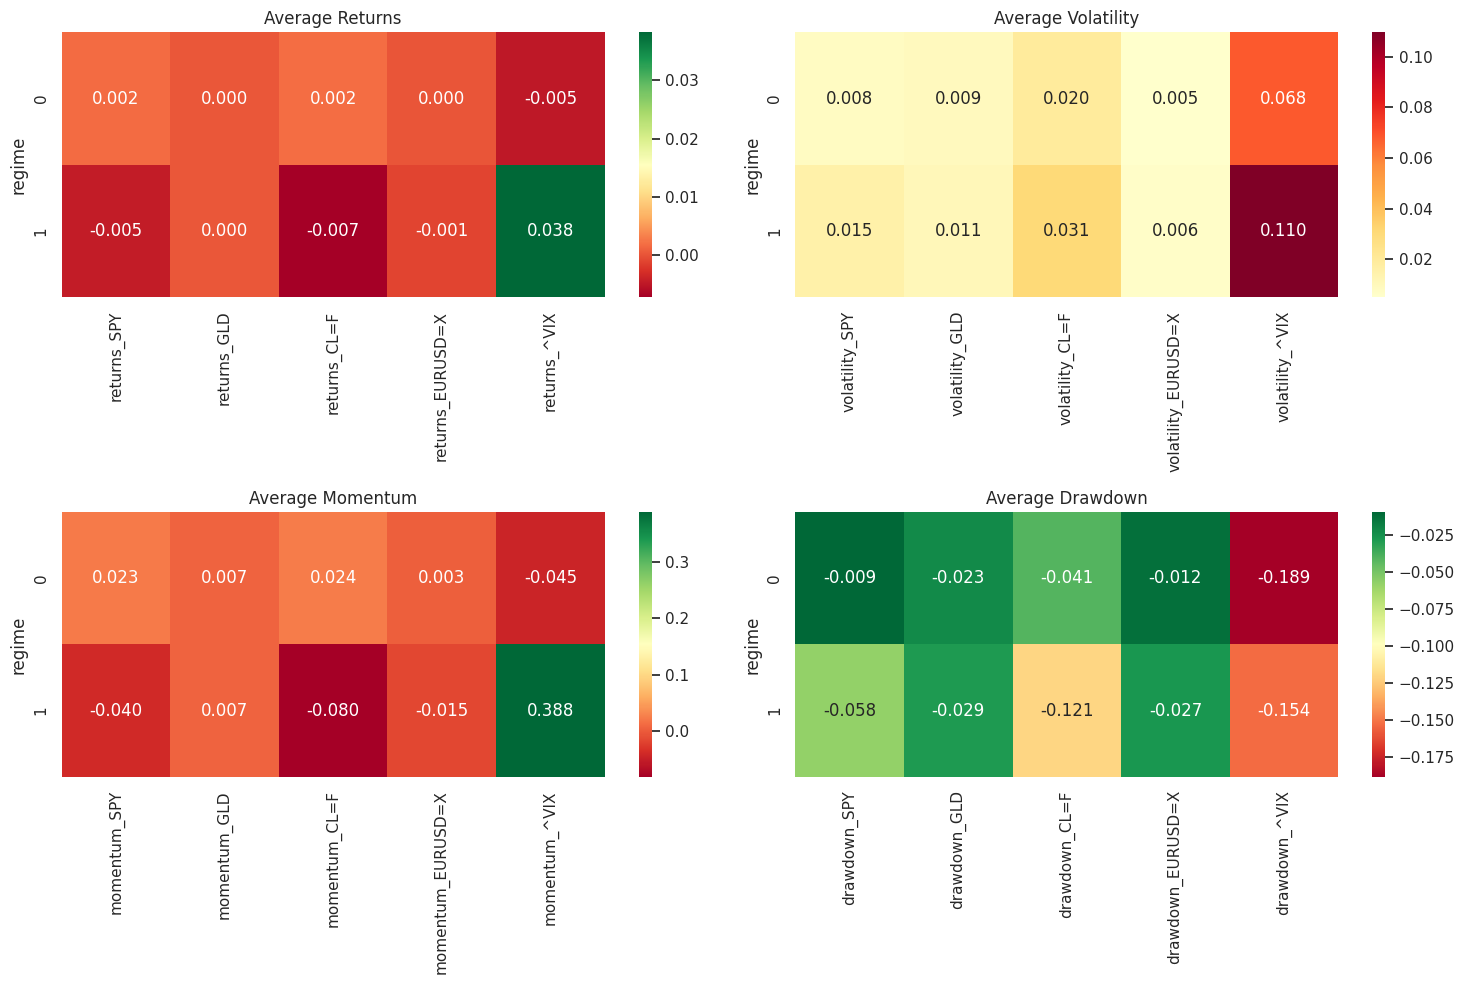

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.heatmap(
    regime_profiles[[c for c in features.columns if c.startswith("returns_")]],
    annot=True, fmt=".3f", cmap="RdYlGn", ax=axes[0, 0]
)
axes[0, 0].set_title("Average Returns")

sns.heatmap(
    regime_profiles[[c for c in features.columns if c.startswith("volatility_")]],
    annot=True, fmt=".3f", cmap="YlOrRd", ax=axes[0, 1]
)
axes[0, 1].set_title("Average Volatility")

sns.heatmap(
    regime_profiles[[c for c in features.columns if c.startswith("momentum_")]],
    annot=True, fmt=".3f", cmap="RdYlGn", ax=axes[1, 0]
)
axes[1, 0].set_title("Average Momentum")

sns.heatmap(
    regime_profiles[[c for c in features.columns if c.startswith("drawdown_")]],
    annot=True, fmt=".3f", cmap="RdYlGn", ax=axes[1, 1]
)
axes[1, 1].set_title("Average Drawdown")

plt.tight_layout()
plt.show()


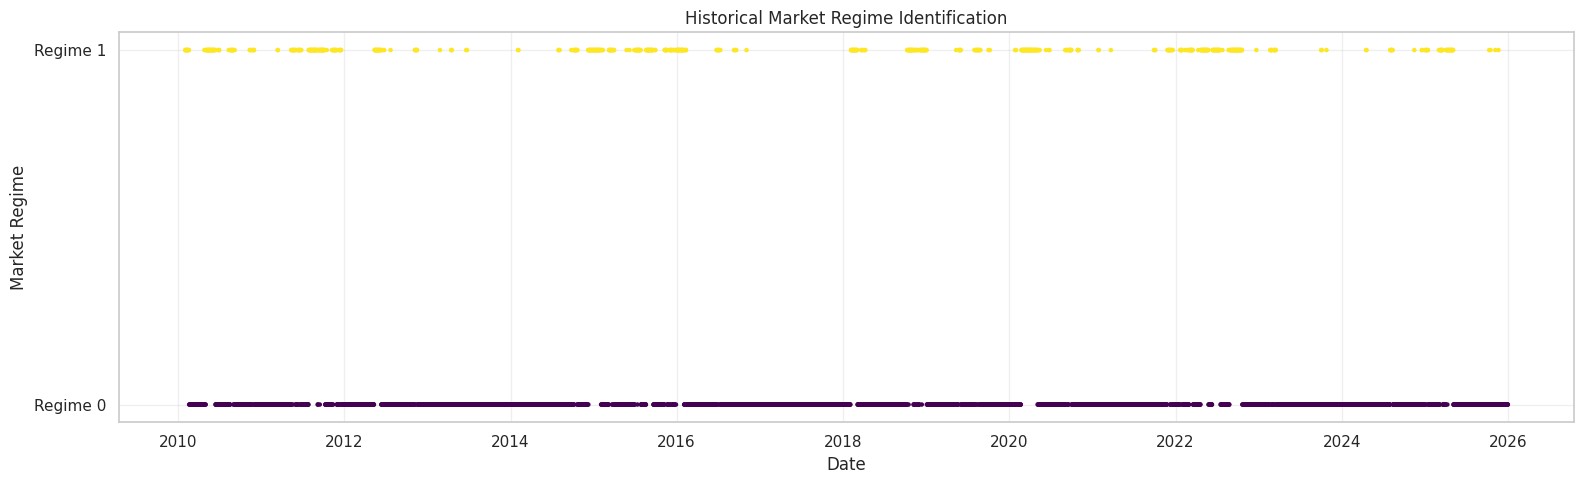

In [ ]:

plt.figure(figsize=(16, 5))

plt.scatter(
    regime_data.index,
    regime_data["regime"],
    c=regime_data["regime"],
    cmap="viridis",
    s=5
)

plt.yticks([0, 1], ["Regime 0", "Regime 1"])
plt.xlabel("Date")
plt.ylabel("Market Regime")
plt.title("Historical Market Regime Identification")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Temporal analysis

In [ ]:

regimes = regime_data["regime"]

episode_id = regimes.ne(regimes.shift()).cumsum()

episodes = pd.DataFrame({
    "regime": regimes,
    "episode_id": episode_id
})

regime_episodes = episodes.groupby("episode_id").agg(
    regime=("regime", "first"),
    start_date=("regime", lambda x: x.index.min()),
    end_date=("regime", lambda x: x.index.max()),
    duration=("regime", "size")
)

display(regime_episodes.head(10))

print("Total regime episodes:", len(regime_episodes))


,regime,start_date,end_date,duration
episode_id,,,,
1,1,2010-02-02,2010-02-18,12
2,0,2010-02-19,2010-04-26,46
3,1,2010-04-27,2010-04-27,1
4,0,2010-04-28,2010-05-03,4
5,1,2010-05-04,2010-06-14,29
6,0,2010-06-15,2010-06-28,10
7,1,2010-06-29,2010-07-01,3
8,0,2010-07-02,2010-08-11,28
9,1,2010-08-12,2010-08-12,1


Total regime episodes: 334


In [ ]:

duration_stats = regime_episodes.groupby("regime")["duration"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

display(duration_stats.round(2))


,count,mean,median,min,max,std
regime,,,,,,
0,167,19.56,3.0,1,310,38.06
1,167,4.37,1.0,1,49,7.39


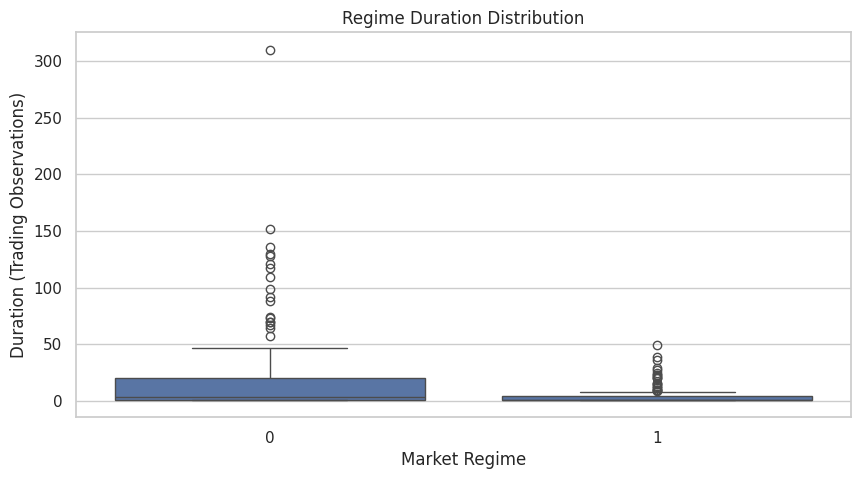

In [ ]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=regime_episodes,
    x="regime",
    y="duration"
)

plt.title("Regime Duration Distribution")
plt.xlabel("Market Regime")
plt.ylabel("Duration (Trading Observations)")

plt.show()


Transition Probability matrix

In [ ]:

transition_matrix = pd.crosstab(
    regimes.iloc[:-1].to_numpy(),
    regimes.iloc[1:].to_numpy(),
    normalize="index"
)

transition_matrix = transition_matrix.reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
)

display(transition_matrix)


col_0,0,1
row_0,,
0,0.949158,0.050842
1,0.229081,0.770919


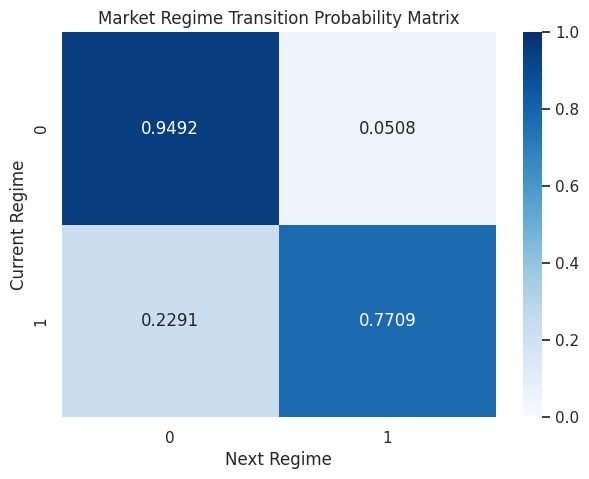

In [ ]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    transition_matrix,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Market Regime Transition Probability Matrix")
plt.xlabel("Next Regime")
plt.ylabel("Current Regime")

plt.show()


In [ ]:

regime_episodes.to_csv(
    "/content/regime_episodes.csv"
)

duration_stats.to_csv(
    "/content/regime_duration_statistics.csv"
)

transition_matrix.to_csv(
    "/content/regime_transition_matrix.csv"
)

print("Temporal analysis results saved.")


Temporal analysis results saved.


In [ ]:
STRESS = regime_data.groupby("regime")["volatility_SPY"].mean().idxmax()
STABLE = 1 - STRESS
print("Stress regime label:", STRESS, "| Stable regime label:", STABLE)

Stress regime label: 1 | Stable regime label: 0


In [ ]:
top_stress = (regime_episodes[regime_episodes["regime"] == STRESS]
              .sort_values("duration", ascending=False).head(10))
display(top_stress)
top_stress.to_csv("/content/top_stress_episodes.csv")

,regime,start_date,end_date,duration
episode_id,,,,
217,1,2020-02-24,2020-05-04,49
283,1,2022-08-26,2022-10-20,39
97,1,2014-12-10,2015-02-02,36
5,1,2010-05-04,2010-06-14,29
37,1,2011-07-29,2011-09-06,27
275,1,2022-04-21,2022-05-25,25
277,1,2022-06-13,2022-07-15,23
143,1,2015-12-30,2016-02-02,23
123,1,2015-08-20,2015-09-18,21


In [ ]:
events = {
    "2010 Flash crash / euro debt": ("2010-04-26", "2010-07-02"),
    "2011 US downgrade / euro crisis": ("2011-07-25", "2011-10-31"),
    "2015-16 China devaluation / oil slump": ("2015-08-17", "2016-02-29"),
    "2018 Q4 sell-off": ("2018-10-01", "2018-12-31"),
    "2020 COVID crash": ("2020-02-20", "2020-04-30"),
    "2022 rate-hike bear market": ("2022-01-03", "2022-10-31"),
    "2025 tariff shock": ("2025-04-01", "2025-04-30"),
}
base_rate = (regime_data["regime"] == STRESS).mean()
rows = []
for name, (s, e) in events.items():
    w = regime_data.loc[s:e, "regime"]
    rows.append({"Event": name, "Start": s, "End": e, "Trading days": len(w),
                 "% days in stress regime": round(100 * (w == STRESS).mean(), 1)})
event_table = pd.DataFrame(rows)
print(f"Base rate (whole sample): {100 * base_rate:.1f}% of days in stress regime")
display(event_table)
event_table.to_csv("/content/event_validation.csv", index=False)

Base rate (whole sample): 18.2% of days in stress regime


,Event,Start,End,Trading days,% days in stress regime
0,2010 Flash crash / euro debt,2010-04-26,2010-07-02,49,67.3
1,2011 US downgrade / euro crisis,2011-07-25,2011-10-31,70,68.6
2,2015-16 China devaluation / oil slump,2015-08-17,2016-02-29,135,51.1
3,2018 Q4 sell-off,2018-10-01,2018-12-31,63,68.3
4,2020 COVID crash,2020-02-20,2020-04-30,49,95.9
5,2022 rate-hike bear market,2022-01-03,2022-10-31,209,53.1
6,2025 tariff shock,2025-04-01,2025-04-30,20,85.0


In [53]:
from sklearn.metrics import adjusted_rand_score
share = (regime_data["regime"] == STRESS).mean()
vix = prices_clean.loc[regime_data.index, "^VIX"]
threshold = vix.quantile(1 - share)
baseline = (vix > threshold).astype(int)                       # 1 = stress day
kmeans_stress = (regime_data["regime"] == STRESS).astype(int)  # 1 = stress day
print(f"VIX threshold: {threshold:.2f} (the {100 * (1 - share):.1f}th percentile)")
print(f"Baseline stress share: {100 * baseline.mean():.1f}%")
print(f"Agreement with K-Means: {100 * (baseline == kmeans_stress).mean():.1f}% of days")
print(f"ARI (K-Means vs baseline): {adjusted_rand_score(kmeans_stress, baseline):.4f}")
rows = []
for name, (s, e) in events.items():
    rows.append({"Event": name,
                 "K-Means stress %": round(100 * kmeans_stress.loc[s:e].mean(), 1),
                 "VIX baseline stress %": round(100 * baseline.loc[s:e].mean(), 1)})
display(pd.DataFrame(rows))
in_event = pd.Series(False, index=regime_data.index)
for s, e in events.values():
    in_event.loc[s:e] = True
print(f"Inside events:  K-Means {100 * kmeans_stress[in_event].mean():.1f}% | VIX {100 * baseline[in_event].mean():.1f}%")
print(f"Outside events: K-Means {100 * kmeans_stress[~in_event].mean():.1f}% | VIX {100 * baseline[~in_event].mean():.1f}%")

VIX threshold: 22.89 (the 81.8th percentile)
Baseline stress share: 18.2%
Agreement with K-Means: 85.0% of days
ARI (K-Means vs baseline): 0.3919


,Event,K-Means stress %,VIX baseline stress %
0,2010 Flash crash / euro debt,67.3,87.8
1,2011 US downgrade / euro crisis,68.6,97.1
2,2015-16 China devaluation / oil slump,51.1,29.6
3,2018 Q4 sell-off,68.3,28.6
4,2020 COVID crash,95.9,95.9
5,2022 rate-hike bear market,53.1,74.6
6,2025 tariff shock,85.0,90.0


Inside events:  K-Means 61.8% | VIX 65.5%
Outside events: K-Means 10.6% | VIX 10.0%


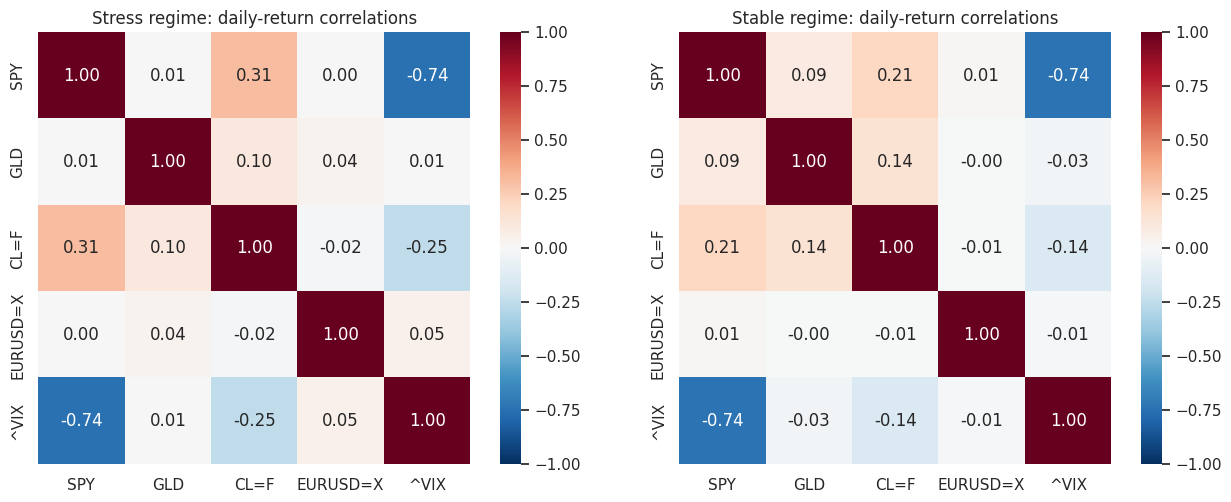

In [ ]:
return_cols = [c for c in features.columns if c.startswith("returns_")]
nice = [c.replace("returns_", "") for c in return_cols]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, r, title in zip(axes, [STRESS, STABLE], ["Stress regime", "Stable regime"]):
    corr = regime_data.loc[regime_data["regime"] == r, return_cols].corr()
    corr.index = nice; corr.columns = nice
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True)
    ax.set_title(f"{title}: daily-return correlations")
    corr.to_csv(f"/content/corr_{title.split()[0].lower()}.csv")
plt.tight_layout(); plt.savefig("/content/fig_regime_correlations.png", dpi=300); plt.show()

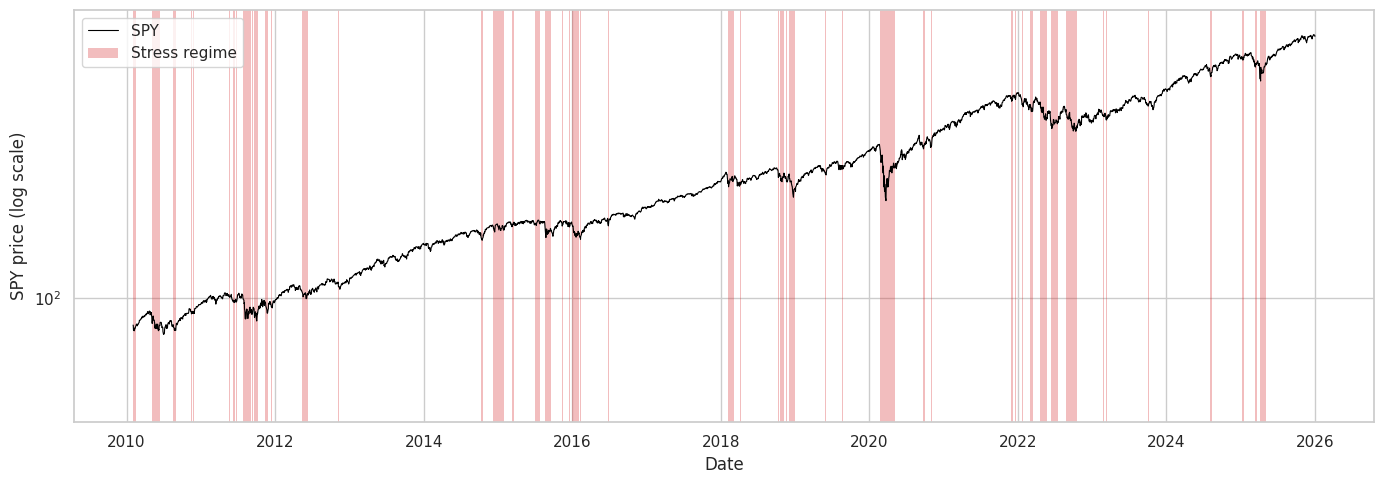

In [ ]:
spy = prices_clean.loc[regime_data.index, "SPY"]
stress_mask = (regime_data["regime"] == STRESS).to_numpy()
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(spy.index, spy.to_numpy(), color="black", linewidth=0.8, label="SPY")
ax.fill_between(spy.index, 0, 1, where=stress_mask, transform=ax.get_xaxis_transform(),
                color="tab:red", alpha=0.3, linewidth=0, label="Stress regime")
ax.set_yscale("log")
ax.set_xlabel("Date"); ax.set_ylabel("SPY price (log scale)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("/content/fig_regime_timeline.png", dpi=300); plt.show()

Robustness analysis

15 day features

In [ ]:

window = ROBUSTNESS_WINDOW

returns_15 = prices_clean.pct_change()

volatility_15 = returns_15.rolling(window).std()

momentum_15 = prices_clean.pct_change(periods=window)

rolling_peak_15 = prices_clean.rolling(window).max()

drawdown_15 = prices_clean / rolling_peak_15 - 1

features_15 = pd.concat(
    {
        "returns": returns_15,
        "volatility": volatility_15,
        "momentum": momentum_15,
        "drawdown": drawdown_15
    },
    axis=1
)

features_15.columns = [
    f"{feature}_{ticker}"
    for feature, ticker in features_15.columns
]

features_15 = features_15.replace(
    [np.inf, -np.inf], np.nan
).dropna()

print("15-day feature matrix:", features_15.shape)

display(features_15.head())


15-day feature matrix: (4000, 20)


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX,momentum_SPY,momentum_GLD,momentum_CL=F,momentum_EURUSD=X,momentum_^VIX,drawdown_SPY,drawdown_GLD,drawdown_CL=F,drawdown_EURUSD=X,drawdown_^VIX
Date,,,,,,,,,,,,,,,,,,,,
2010-01-26,-0.004191,0.000744,-0.007308,-0.004788,-0.033845,0.010059,0.011752,0.012695,0.005494,0.085104,-0.035472,-0.020401,-0.083425,-0.023687,0.225050,-0.049974,-0.046876,-0.101827,-0.030404,-0.101062
2010-01-27,0.004757,-0.009576,-0.013921,-0.003648,-0.057434,0.010149,0.011943,0.012606,0.005483,0.086290,-0.033442,-0.028897,-0.099058,-0.023320,0.195866,-0.045454,-0.056004,-0.114330,-0.033941,-0.152691
2010-01-28,-0.011472,-0.000469,-0.000407,-0.004484,0.025497,0.010383,0.010829,0.010905,0.005401,0.086041,-0.045203,-0.045108,-0.114691,-0.030269,0.238518,-0.056405,-0.056447,-0.110091,-0.038272,-0.131088
2010-01-29,-0.010869,-0.004884,-0.010185,-0.007239,0.037505,0.010361,0.010807,0.010907,0.005476,0.085942,-0.059550,-0.043855,-0.118195,-0.031506,0.291710,-0.066661,-0.061054,-0.119154,-0.045234,-0.098499
2010-02-01,0.015551,0.022556,0.021128,0.004331,-0.082453,0.011409,0.012540,0.013137,0.005257,0.088284,-0.048093,-0.027117,-0.100544,-0.033592,0.246001,-0.052147,-0.039876,-0.098037,-0.041098,-0.172830


standardizartion for 15 day features

In [ ]:

scaler_15 = StandardScaler()

X_scaled_15 = scaler_15.fit_transform(features_15)

pca_15 = PCA()

X_pca_15 = pca_15.fit_transform(X_scaled_15)

cumulative_variance_15 = np.cumsum(
    pca_15.explained_variance_ratio_
)

n_components_15 = np.argmax(
    cumulative_variance_15 >= PCA_VARIANCE_THRESHOLD
) + 1

pca_final_15 = PCA(
    n_components=n_components_15
)

X_reduced_15 = pca_final_15.fit_transform(
    X_scaled_15
)

print("Selected components:", n_components_15)

print(
    "Explained variance:",
    round(
        pca_final_15.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

print("Reduced matrix shape:", X_reduced_15.shape)


Selected components: 14
Explained variance: 95.51 %
Reduced matrix shape: (4000, 14)


K Means for 15 day features

k = 2

In [ ]:

kmeans_15 = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

labels_15 = kmeans_15.fit_predict(X_reduced_15)

regime_data_15 = features_15.copy()

regime_data_15["regime"] = labels_15

silhouette_15 = silhouette_score(
    X_reduced_15, labels_15
)

db_15 = davies_bouldin_score(
    X_reduced_15, labels_15
)

print("15-day Silhouette Score:", silhouette_15)
print("15-day Davies-Bouldin Index:", db_15)

print("\nCluster sizes:")
print(regime_data_15["regime"].value_counts().sort_index())


15-day Silhouette Score: 0.28076744540900206
15-day Davies-Bouldin Index: 2.2078510333882115

Cluster sizes:
regime
0     827
1    3173
Name: count, dtype: int64


comparision of 15 day and 20 day regimes

In [ ]:

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

common_dates = regime_data.index.intersection(
    regime_data_15.index
)

labels_20_common = regime_data.loc[
    common_dates, "regime"
]

labels_15_common = regime_data_15.loc[
    common_dates, "regime"
]

contingency = pd.crosstab(
    labels_20_common,
    labels_15_common
)

row_ind, col_ind = linear_sum_assignment(
    -contingency.to_numpy()
)

label_mapping = {
    contingency.columns[j]: contingency.index[i]
    for i, j in zip(row_ind, col_ind)
}

aligned_labels_15 = labels_15_common.map(label_mapping)

comparison = pd.DataFrame({
    "20_day_regime": labels_20_common,
    "15_day_regime": aligned_labels_15
})

print("Label mapping:", label_mapping)

print("\nAligned comparison:")
display(pd.crosstab(
    comparison["20_day_regime"],
    comparison["15_day_regime"]
))

ari = adjusted_rand_score(
    labels_20_common,
    labels_15_common
)

print("\nAdjusted Rand Index:", round(ari, 4))


Label mapping: {np.int32(1): np.int32(0), np.int32(0): np.int32(1)}

Aligned comparison:


15_day_regime,0,1
20_day_regime,,
0,3074,192
1,99,630



Adjusted Rand Index: 0.686


In [ ]:

profile_20 = regime_data.groupby("regime").mean()

profile_15 = regime_data_15.groupby("regime").mean()

profile_15.index = profile_15.index.map(label_mapping)

profile_15 = profile_15.sort_index()

print("20-day regime profiles:")
display(profile_20.round(4))

print("\n15-day regime profiles:")
display(profile_15.round(4))


20-day regime profiles:


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX,momentum_SPY,momentum_GLD,momentum_CL=F,momentum_EURUSD=X,momentum_^VIX,drawdown_SPY,drawdown_GLD,drawdown_CL=F,drawdown_EURUSD=X,drawdown_^VIX
regime,,,,,,,,,,,,,,,,,,,,
0,0.0017,0.0004,0.0020,0.0002,-0.0048,0.0079,0.0090,0.0195,0.0049,0.0682,0.0229,0.0074,0.0241,0.0025,-0.0452,-0.0094,-0.0227,-0.0411,-0.0123,-0.1887
1,-0.0045,0.0002,-0.0072,-0.0011,0.0382,0.0154,0.0107,0.0306,0.0064,0.1097,-0.0400,0.0072,-0.0805,-0.0151,0.3884,-0.0582,-0.0289,-0.1205,-0.0271,-0.1536



15-day regime profiles:


,returns_SPY,returns_GLD,returns_CL=F,returns_EURUSD=X,returns_^VIX,volatility_SPY,volatility_GLD,volatility_CL=F,volatility_EURUSD=X,volatility_^VIX,momentum_SPY,momentum_GLD,momentum_CL=F,momentum_EURUSD=X,momentum_^VIX,drawdown_SPY,drawdown_GLD,drawdown_CL=F,drawdown_EURUSD=X,drawdown_^VIX
regime,,,,,,,,,,,,,,,,,,,,
0,0.0019,0.0004,0.0019,0.0004,-0.0056,0.0077,0.0088,0.0192,0.0048,0.0657,0.0197,0.0071,0.0206,0.0026,-0.0471,-0.0075,-0.0182,-0.0340,-0.0100,-0.1623
1,-0.0043,0.0002,-0.0059,-0.0016,0.0362,0.0147,0.0108,0.0295,0.0062,0.1091,-0.0343,-0.0004,-0.0617,-0.0126,0.3152,-0.0487,-0.0275,-0.0975,-0.0224,-0.1270


In [ ]:

robustness_metrics = pd.DataFrame({
    "Lookback Window": ["20-day", "15-day"],
    "Silhouette Score": [
        results_df.loc[
            results_df["k"] == best_k,
            "Silhouette Score"
        ].iloc[0],
        silhouette_15
    ],
    "Davies-Bouldin Index": [
        results_df.loc[
            results_df["k"] == best_k,
            "Davies-Bouldin Index"
        ].iloc[0],
        db_15
    ]
})

display(robustness_metrics)


,Lookback Window,Silhouette Score,Davies-Bouldin Index
0,20-day,0.294647,2.155200
1,15-day,0.280767,2.207851


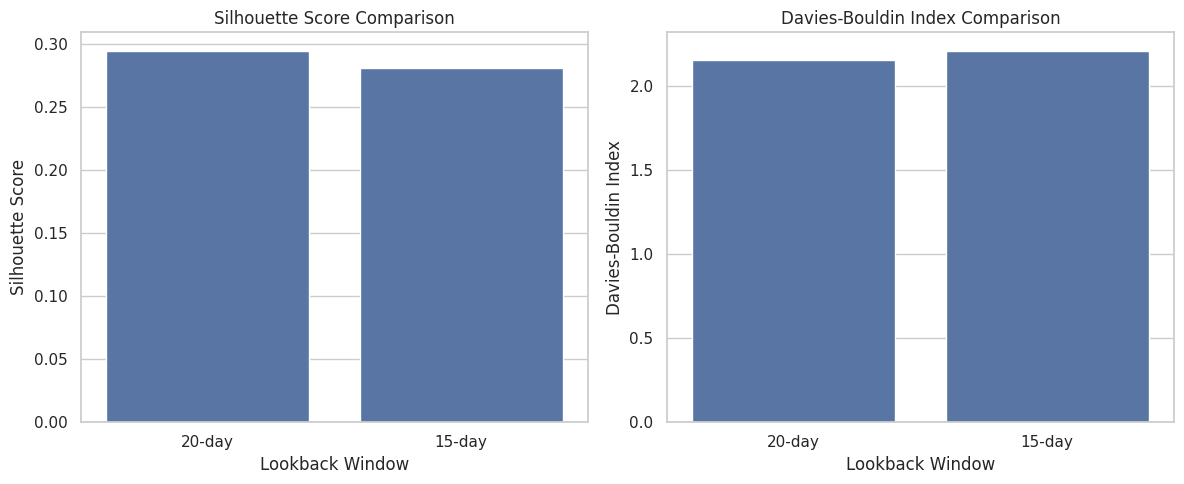

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=robustness_metrics,
    x="Lookback Window",
    y="Silhouette Score",
    ax=axes[0]
)
axes[0].set_title("Silhouette Score Comparison")

sns.barplot(
    data=robustness_metrics,
    x="Lookback Window",
    y="Davies-Bouldin Index",
    ax=axes[1]
)
axes[1].set_title("Davies-Bouldin Index Comparison")

plt.tight_layout()
plt.show()


In [ ]:

features_15.to_csv("/content/features_15day.csv")

regime_data_15.to_csv("/content/regimes_15day.csv")

robustness_metrics.to_csv(
    "/content/robustness_metrics.csv",
    index=False
)

comparison.to_csv("/content/regime_comparison.csv")

print("Robustness analysis completed and saved.")


Robustness analysis completed and saved.


In [ ]:
lab4 = pd.Series(models[4]["labels"], index=X_reduced.index)
lab5 = pd.Series(models[5]["labels"], index=X_reduced.index)
s4 = lab4.value_counts().idxmin(); s5 = lab5.value_counts().idxmin()
print("k=4 smallest cluster:", (lab4 == s4).sum(), "obs, dates:", list(lab4[lab4 == s4].index.date[:5]))
print("k=5 smallest cluster:", lab5[lab5 == s5].index.min().date(), "to", lab5[lab5 == s5].index.max().date())
print(prices_clean.loc["2020-04-16":"2020-04-23", "CL=F"])

k=4 smallest cluster: 129 obs, dates: [datetime.date(2010, 5, 10), datetime.date(2010, 5, 12), datetime.date(2010, 5, 17), datetime.date(2010, 5, 19), datetime.date(2010, 5, 21)]
k=5 smallest cluster: 2020-03-09 to 2020-04-21
Date
2020-04-16    19.870001
2020-04-17    18.270000
2020-04-21    10.010000
2020-04-22    13.780000
2020-04-23    16.500000
Name: CL=F, dtype: float64
